Part 1: Imports and Data Loading

In [1]:
# Core Libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, f1_score

# Load dataset
df = pd.read_csv("pharma_amm_data.csv")

Part 2: Data Exploration

In [2]:
# Basic info
print("Data shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# Data types
print("\nData types:")
print(df.dtypes)

# Statistical summary
print("\nSummary statistics:")
print(df.describe())

# Missing values check
print("\nMissing values:")
print(df.isnull().sum())

Data shape: (1000, 12)

First 5 rows:
     amm_number product_name        manufacturer submission_date  \
0  AMM-2023-001    MediSafeX          PharmaCorp      2023-03-12   
1  AMM-2023-002    QuickHeal  BioPharm Solutions      2023-04-18   
2  AMM-2023-003    MediSafeX            MediVita      2023-03-30   
3  AMM-2023-004     PainAway  BioPharm Solutions      2023-02-19   
4  AMM-2023-005     PainAway            MediVita      2023-02-23   

  approval_date  clinical_trial_participants  reported_side_effects  \
0    2023-04-30                          581                    119   
1    2023-07-13                          483                    111   
2    2023-05-26                         1627                    145   
3    2023-04-15                         1151                     79   
4    2023-04-27                         1945                    166   

   batch_size  price_per_unit  production_cost  is_fraud  \
0       30000           66.94             6.55         1   
1     

In [3]:
# Handle missing values properly
df = df.assign(
    manufacturer=df['manufacturer'].fillna('Unknown'),
    batch_size=df['batch_size'].fillna(df['batch_size'].median())
)

# Check for duplicates
print("\nDuplicate AMM numbers:", df['amm_number'].duplicated().sum())

# Convert dates
df['submission_date'] = pd.to_datetime(df['submission_date'])
df['approval_date'] = pd.to_datetime(df['approval_date'])


Duplicate AMM numbers: 0


In [4]:
# Time-based feature
df['approval_time'] = (df['approval_date'] - df['submission_date']).dt.days

# Ratio features
df['price_to_cost_ratio'] = df['price_per_unit'] / df['production_cost']
median_batch = df['batch_size'].median()
df['batch_size_variation'] = df['batch_size'] / median_batch

# Binary flag
df['fast_approval'] = (df['approval_time'] < 30).astype(int)

# Categorical encoding
manufacturer_dummies = pd.get_dummies(df['manufacturer'], prefix='manufacturer')
df = pd.concat([df, manufacturer_dummies], axis=1)

In [5]:
# Define features
features = [
    'approval_time',
    'price_to_cost_ratio',
    'batch_size_variation',
    ##'fast_approval',
    'clinical_trial_participants',
    'reported_side_effects'
] + [col for col in df.columns if col.startswith('manufacturer_')]

X = df[features]
y = df['is_fraud']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    random_state=42
)

In [6]:
# Initialize model
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,           # prevents overfitting
    min_samples_leaf=15,   # each leaf needs 15+ samples
    max_features='sqrt',
    class_weight='balanced',
    random_state=42
)

# Train model
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",15
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [7]:
# Predictions
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

# Performance metrics
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nAUC-ROC Score:", roc_auc_score(y_test, y_proba))

# Feature importance
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nFeature Importance:")
print(feature_importance)


Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       211
           1       0.92      0.89      0.90        89

    accuracy                           0.94       300
   macro avg       0.94      0.93      0.93       300
weighted avg       0.94      0.94      0.94       300


AUC-ROC Score: 0.9305074817615421

Feature Importance:
                           Feature  Importance
1              price_to_cost_ratio    0.549755
3      clinical_trial_participants    0.161744
2             batch_size_variation    0.143250
4            reported_side_effects    0.099044
0                    approval_time    0.037205
5  manufacturer_BioPharm Solutions    0.004594
7           manufacturer_HealthGen    0.001596
9          manufacturer_PharmaCorp    0.001346
8            manufacturer_MediVita    0.000854
6             manufacturer_CureAll    0.000611


In [8]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=5000, 
        class_weight='balanced', 
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight='balanced', 
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=6,
        min_samples_leaf=8,
        max_features='sqrt',
        class_weight='balanced',
        random_state=42
    ),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=100, max_depth=4, random_state=42),

    "XGBoost": XGBClassifier(
        eval_metric='logloss',
        random_state=42
    ),
    "SVM": SVC(
        probability=True, 
        class_weight='balanced', 
        random_state=42)
}
results = []
for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred  = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]
    results.append({
        "Model":     name,
        "Accuracy":  round(accuracy_score(y_test, y_pred), 4),
        "F1-Score":  round(f1_score(y_test, y_pred), 4),
        "AUC-ROC":   round(roc_auc_score(y_test, y_proba), 4)
    })

results_df = pd.DataFrame(results).sort_values("AUC-ROC", ascending=False)
print(results_df.to_string(index=False))

              Model  Accuracy  F1-Score  AUC-ROC
            XGBoost    0.9433    0.9029   0.9386
      Random Forest    0.9433    0.9029   0.9333
  Gradient Boosting    0.9467    0.9091   0.9297
Logistic Regression    0.9267    0.8778   0.9103
                SVM    0.8567    0.7839   0.9033
      Decision Tree    0.9100    0.8492   0.8938


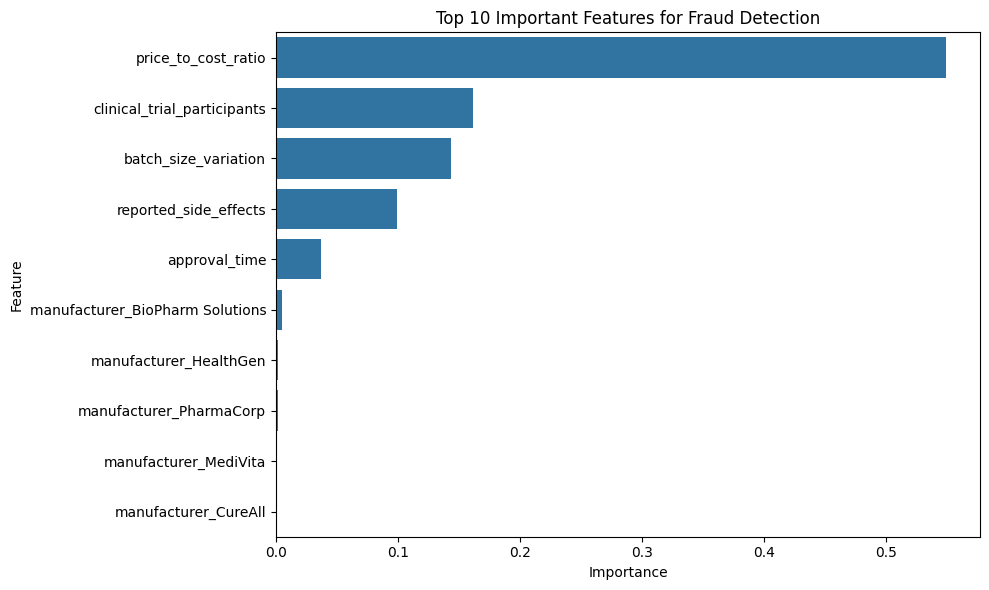

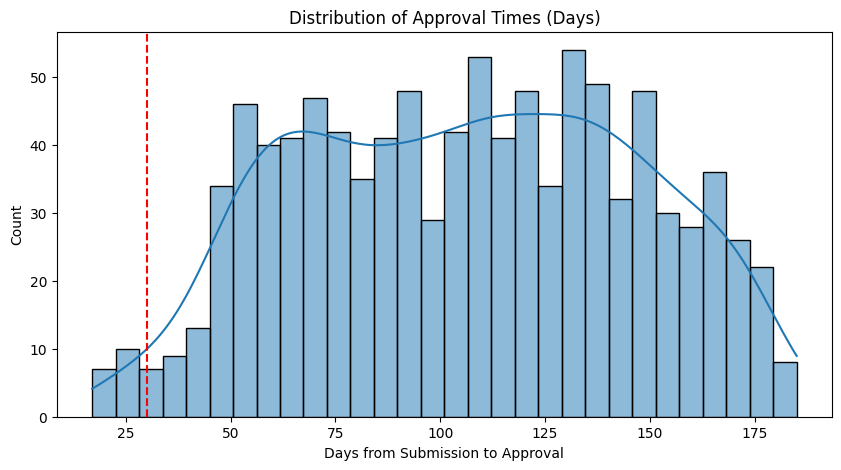

In [9]:
# Feature importance plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=feature_importance.head(10)
)
plt.title('Top 10 Important Features for Fraud Detection')
plt.tight_layout()
plt.show()

# Approval time distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['approval_time'], bins=30, kde=True)
plt.axvline(30, color='r', linestyle='--')
plt.title('Distribution of Approval Times (Days)')
plt.xlabel('Days from Submission to Approval')
plt.show()

In [10]:
# Save processed data
df.to_csv('processed_pharma_data.csv', index=False)

# Save model (requires joblib)
from joblib import dump
dump(model, 'pharma_fraud_model.joblib')

# Save predictions
results = X_test.copy()
results['actual'] = y_test
results['predicted'] = y_pred
results['probability'] = y_proba
results.to_csv('model_predictions.csv', index=False)

In [11]:
# === MODEL EXPORT CELL === (add to end of amm.ipynb)
import joblib
from sklearn.ensemble import RandomForestClassifier

# 1. Ensure you have your trained model
if 'model' not in globals():
    model = RandomForestClassifier().fit(X_train, y_train)  # Fallback if model not defined

# 2. Export with error handling
try:
    joblib.dump(model, 'amm.joblib', compress=3)
    print("✅ Model exported to 'amm.joblib'")
    print(f"Model details: {model.__class__.__name__} (n_estimators={model.n_estimators})")
except Exception as e:
    print(f"❌ Export failed: {str(e)}")

✅ Model exported to 'amm.joblib'
Model details: RandomForestClassifier (n_estimators=100)
